# Exploratory Data Analysis (EDA)

## Chest X-ray Dataset

This notebook explores the chest X-ray dataset, including image counts, class distribution, image dimensions, and sample visualizations.

## 1. Introduction

Exploratory Data Analysis (EDA) is an important initial step in a machine learning project. It helps us understand the structure, quality, distribution, and characteristics of a dataset before training a model.

In this project, EDA is performed on a chest X-ray image dataset containing two classes: **NORMAL** and **PNEUMONIA**. The analysis examines the number of images in each class, the distribution across training, validation, and testing sets, the original image dimensions, image color modes, and image validity.

The findings from this analysis will help guide preprocessing decisions and prepare the dataset for developing a deep learning model for chest X-ray classification.

In [1]:
!pip install -q kaggle

In [2]:
from google.colab import files

uploaded = files.upload()

Saving kaggle.json to kaggle.json


In [3]:
import os
import shutil
from pathlib import Path

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle credentials configured.")

Kaggle credentials configured.


In [4]:
from pathlib import Path
import zipfile
import subprocess

raw_dir = Path("/content/data/raw")
interim_dir = Path("/content/data/interim")
raw_dir.mkdir(parents=True, exist_ok=True)
interim_dir.mkdir(parents=True, exist_ok=True)

subprocess.run([
    "kaggle", "datasets", "download",
    "-d", "paultimothymooney/chest-xray-pneumonia",
    "-p", str(raw_dir)
], check=True)

zip_path = raw_dir / "chest-xray-pneumonia.zip"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(interim_dir)

print("Extraction completed.")
print("Extracted folders:", [p.name for p in interim_dir.iterdir()])

Extraction completed.
Extracted folders: ['chest_xray']


## 2. Dataset Overview

The dataset contains **5,856 chest X-ray images** organized into three subsets: training, validation, and testing.

- **Training set:** 5,216 images
- **Validation set:** 16 images
- **Testing set:** 624 images

Each image belongs to one of two categories: NORMAL or PNEUMONIA. The training set is used to learn model parameters, the validation set can be used to monitor model performance and tune hyperparameters, and the testing set is reserved for evaluating the trained model on unseen data.

**Observation:** The validation set contains only 16 images. This is very small for reliable model selection and performance monitoring. If the project permits, a larger, representative validation set should be considered.

In [5]:
from pathlib import Path

base = Path("/content/data/interim")

for p in base.rglob("train"):
    if p.is_dir() and (p / "NORMAL").is_dir() and (p / "PNEUMONIA").is_dir():
        print("Found training folder:", p)
        print("Expected dataset root:", p.parent)

Found training folder: /content/data/interim/chest_xray/train
Expected dataset root: /content/data/interim/chest_xray
Found training folder: /content/data/interim/chest_xray/chest_xray/train
Expected dataset root: /content/data/interim/chest_xray/chest_xray
Found training folder: /content/data/interim/chest_xray/__MACOSX/chest_xray/train
Expected dataset root: /content/data/interim/chest_xray/__MACOSX/chest_xray


In [6]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image

DATA_DIR = Path("/content/data/interim/chest_xray")

for split in ['train', 'val', 'test']:
    split_dir = DATA_DIR / split
    print(f'\n{split.upper()}')
    if not split_dir.exists():
        print(f'Folder not found: {split_dir}')
        continue
    counts = Counter(
        p.parent.name for p in split_dir.rglob('*')
        if p.is_file() and p.suffix.lower() in {'.jpg', '.jpeg', '.png'}
    )
    print(dict(counts))


TRAIN
{'NORMAL': 1341, 'PNEUMONIA': 3875}

VAL
{'NORMAL': 8, 'PNEUMONIA': 8}

TEST
{'NORMAL': 234, 'PNEUMONIA': 390}


In [7]:

from pathlib import Path
from PIL import Image, UnidentifiedImageError

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("data/interim/chest_xray")

print("Dataset path:", DATA_DIR.resolve())
print("Dataset exists:", DATA_DIR.exists())

for split in ["train", "val", "test"]:
    split_dir = DATA_DIR / split

    print(f"\n{split.upper()}")

    if split_dir.exists():
        for class_dir in sorted(split_dir.iterdir()):
            if class_dir.is_dir():
                print(
                    class_dir.name,
                    "->",
                    len([
                        p for p in class_dir.iterdir()
                        if p.is_file()
                    ]),
                    "files"
                )
    else:
        print("Folder not found:", split_dir)


Dataset path: /content/data/interim/chest_xray
Dataset exists: True

TRAIN
NORMAL -> 1341 files
PNEUMONIA -> 3875 files

VAL
NORMAL -> 8 files
PNEUMONIA -> 8 files

TEST
NORMAL -> 234 files
PNEUMONIA -> 390 files


,Split,Class,Count
0,TRAIN,NORMAL,1341
1,TRAIN,PNEUMONIA,3875
2,VAL,NORMAL,8
3,VAL,PNEUMONIA,8
4,TEST,NORMAL,234
5,TEST,PNEUMONIA,390


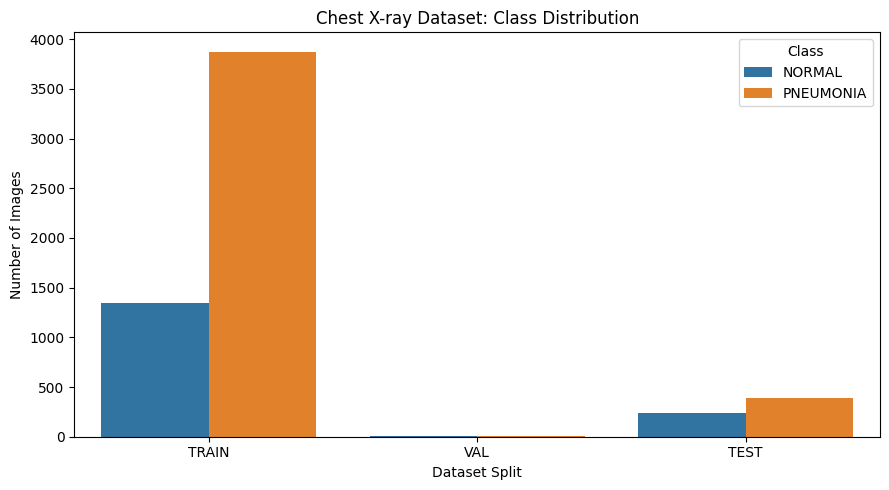

In [8]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("data/interim/chest_xray")

records = []

for split in ["train", "val", "test"]:
    split_dir = DATA_DIR / split

    if not split_dir.exists():
        continue

    for class_dir in sorted(split_dir.iterdir()):
        if class_dir.is_dir():
            count = sum(
                1 for p in class_dir.iterdir()
                if p.is_file()
            )

            records.append({
                "Split": split.upper(),
                "Class": class_dir.name,
                "Count": count
            })

df_counts = pd.DataFrame(records)

display(df_counts)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=df_counts,
    x="Split",
    y="Count",
    hue="Class"
)
plt.title("Chest X-ray Dataset: Class Distribution")
plt.ylabel("Number of Images")
plt.xlabel("Dataset Split")
plt.tight_layout()
plt.show()


## 3. Class Distribution Analysis

The dataset contains the following class distribution:

- **PNEUMONIA:** 4,273 images (72.97%)
- **NORMAL:** 1,583 images (27.03%)

The analysis shows that the dataset is imbalanced, with pneumonia images representing approximately 73% of all images. The number of pneumonia images is substantially higher than the number of normal images.

**Impact on model training:** A model trained on this dataset may become biased toward predicting the majority class. Therefore, accuracy alone may not provide a complete picture of model performance.

**Recommendation:** Evaluate the model using precision, recall, F1-score, a confusion matrix, and class-wise sensitivity. Class weighting or other imbalance-handling techniques can also be investigated if needed.

In [11]:

from pathlib import Path
import pandas as pd

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

records = []

for split in ["train", "val", "test"]:
    split_dir = DATA_DIR / split

    if not split_dir.exists():
        continue

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        for path in class_dir.rglob("*"):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({
                    "filepath": str(path),
                    "filename": path.name,
                    "split": split,
                    "class_name": class_dir.name,
                    "extension": path.suffix.lower()
                })

df = pd.DataFrame(records)

print("Total images:", len(df))
print("Metadata shape:", df.shape)
display(df.head())


Total images: 5856
Metadata shape: (5856, 5)


,filepath,filename,split,class_name,extension
0,data/interim/chest_xray/train/NORMAL/IM-0487-0...,IM-0487-0001.jpeg,train,NORMAL,.jpeg
1,data/interim/chest_xray/train/NORMAL/NORMAL2-I...,NORMAL2-IM-1152-0001-0001.jpeg,train,NORMAL,.jpeg
2,data/interim/chest_xray/train/NORMAL/NORMAL2-I...,NORMAL2-IM-0445-0001.jpeg,train,NORMAL,.jpeg
3,data/interim/chest_xray/train/NORMAL/IM-0687-0...,IM-0687-0001.jpeg,train,NORMAL,.jpeg
4,data/interim/chest_xray/train/NORMAL/IM-0748-0...,IM-0748-0001.jpeg,train,NORMAL,.jpeg


In [12]:

print("\nImages per class:")
print(df["class_name"].value_counts())

print("\nImages per split:")
print(df["split"].value_counts())

print("\nClass distribution by split:")
display(pd.crosstab(df["split"], df["class_name"]))



Images per class:
class_name
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

Images per split:
split
train    5216
test      624
val        16
Name: count, dtype: int64

Class distribution by split:


class_name,NORMAL,PNEUMONIA
split,,
test,234,390
train,1341,3875
val,8,8


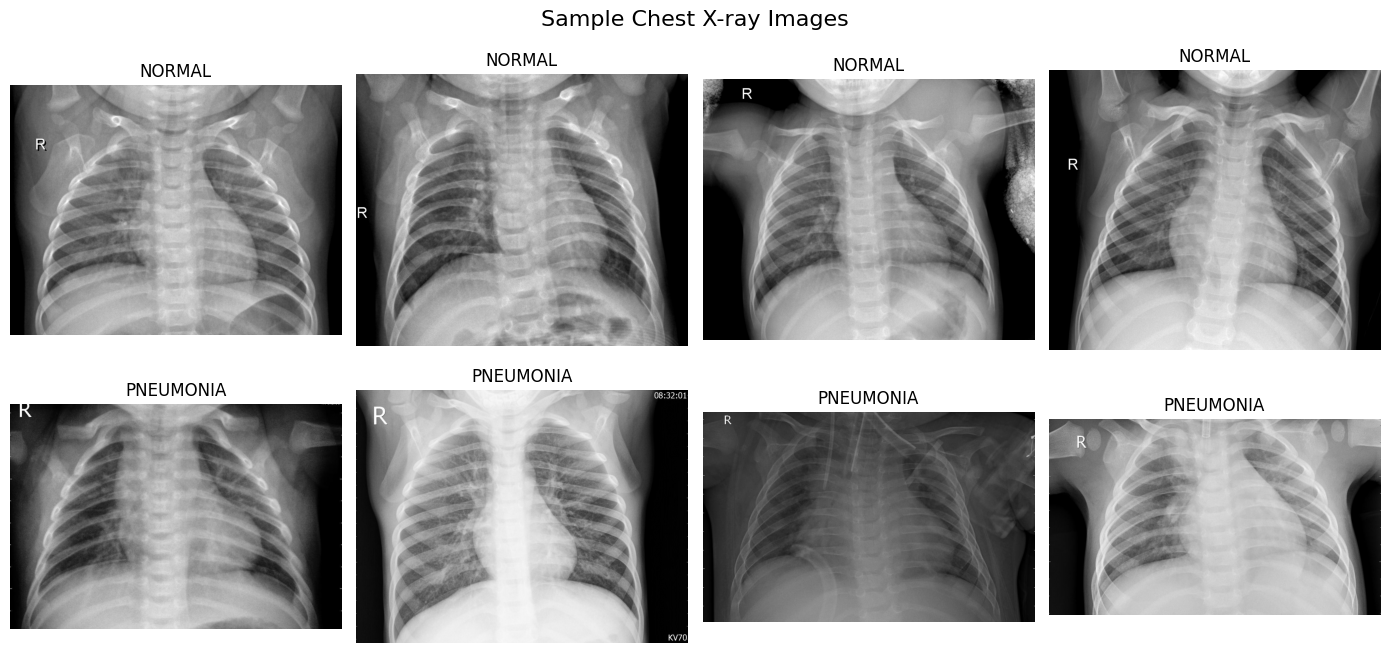

In [9]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

DATA_DIR = Path("data/interim/chest_xray")
random.seed(42)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for row, class_name in enumerate(["NORMAL", "PNEUMONIA"]):
    image_dir = DATA_DIR / "train" / class_name

    image_paths = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ]

    samples = random.sample(image_paths, min(4, len(image_paths)))

    for col, image_path in enumerate(samples):
        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("L"), cmap="gray")

        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.suptitle("Sample Chest X-ray Images", fontsize=16)
plt.tight_layout()
plt.show()


## 4. Visual Inspection of Chest X-ray Images

Representative images from both the NORMAL and PNEUMONIA classes were visualized to understand the appearance of the input data.

Chest X-ray images contain anatomical structures such as the lungs, ribs, and surrounding tissues. Images in the pneumonia category may exhibit abnormal patterns or areas of increased opacity, while normal images may show fewer visible abnormalities.

However, visual appearances can overlap, and the differences are not always obvious. This makes automated classification a challenging task that requires careful preprocessing and model evaluation.

The sample images are displayed in grayscale to provide a consistent visual representation. These examples are useful for preliminary inspection but are not sufficient to establish a medical diagnosis.

Class Distribution Summary:


,Image Count,Percentage (%)
class_name,,
PNEUMONIA,4273,72.97
NORMAL,1583,27.03


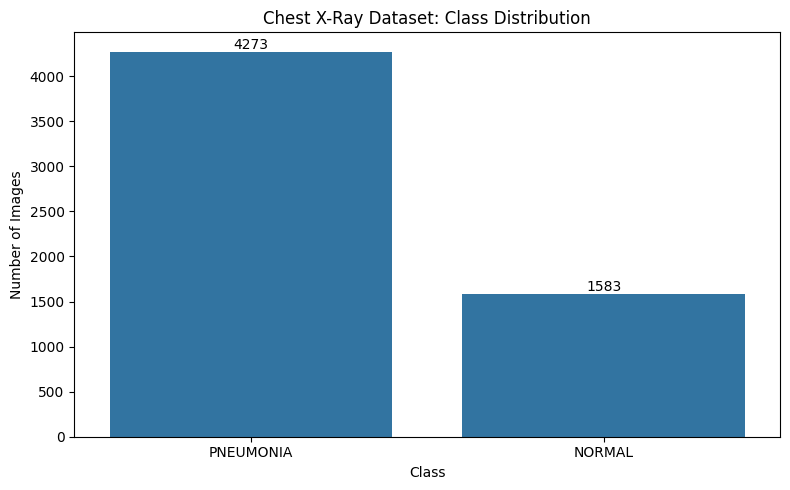

In [13]:

# EDA Step 3: Class Distribution

class_counts = df["class_name"].value_counts()
class_percentages = df["class_name"].value_counts(normalize=True) * 100

# Print actual counts and percentages
summary = pd.DataFrame({
    "Image Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

print("Class Distribution Summary:")
display(summary)

# Create bar chart
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

# Display count above each bar
for i, count in enumerate(class_counts.values):
    ax.text(i, count + 30, str(count), ha="center")

plt.title("Chest X-Ray Dataset: Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()


In [14]:
print("Metadata rows:", len(df))
print("\nClass counts:")
print(df["class_name"].value_counts())

print("\nCounts by split and class:")
display(pd.crosstab(df["split"], df["class_name"], margins=True))

Metadata rows: 5856

Class counts:
class_name
PNEUMONIA    4273
NORMAL       1583
Name: count, dtype: int64

Counts by split and class:


class_name,NORMAL,PNEUMONIA,All
split,,,
test,234,390,624
train,1341,3875,5216
val,8,8,16
All,1583,4273,5856


Class counts across dataset splits:


class_name,NORMAL,PNEUMONIA
split,,
test,234,390
train,1341,3875
val,8,8


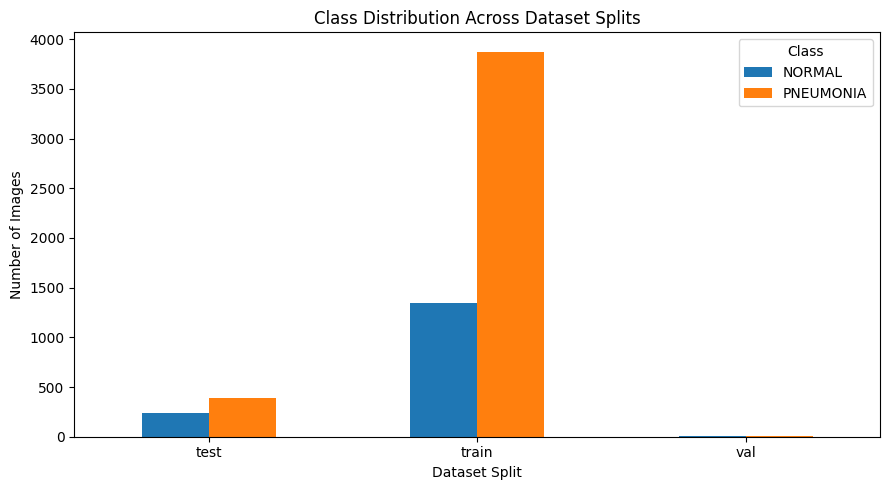

Class percentages within each split:


class_name,NORMAL,PNEUMONIA
split,,
test,37.50,62.50
train,25.71,74.29
val,50.00,50.00


In [15]:

# EDA Step 4: Compare Dataset Splits

split_counts = pd.crosstab(
    df["split"],
    df["class_name"]
)

print("Class counts across dataset splits:")
display(split_counts)

# Plot class counts
ax = split_counts.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Images")
plt.legend(title="Class")
plt.tight_layout()
plt.show()

# Calculate class percentages within each split
print("Class percentages within each split:")
display(
    (split_counts.div(split_counts.sum(axis=1), axis=0) * 100).round(2)
)


## 5. Training, Validation, and Testing Split Analysis

The distribution of classes was examined separately for each dataset split.

| Dataset split | NORMAL | PNEUMONIA | Total |
|---|---:|---:|---:|
| Training | 1,341 | 3,875 | 5,216 |
| Validation | 8 | 8 | 16 |
| Testing | 234 | 390 | 624 |

The training set contains approximately 74.29% pneumonia images and 25.71% normal images. The testing set contains 62.50% pneumonia images and 37.50% normal images. The validation set has equal numbers of images from both classes, but its small size limits the reliability of performance estimates.

**Observation:** The class proportions differ between the training and testing sets. This difference should be considered when interpreting the final evaluation metrics. The split comparison alone does not establish whether images from the same patient occur across multiple subsets.

In [16]:

# EDA Step 5: Analyze Original Image Dimensions

from pathlib import Path
from PIL import Image, UnidentifiedImageError
import pandas as pd

metadata = []

for _, row in df.iterrows():
    try:
        with Image.open(row["filepath"]) as img:
            metadata.append({
                **row.to_dict(),
                "width": img.width,
                "height": img.height,
                "mode": img.mode,
                "file_size_kb": round(
                    Path(row["filepath"]).stat().st_size / 1024, 2
                ),
                "valid_image": True
            })

    except (UnidentifiedImageError, OSError, ValueError):
        metadata.append({
            **row.to_dict(),
            "width": None,
            "height": None,
            "mode": None,
            "file_size_kb": None,
            "valid_image": False
        })

metadata_df = pd.DataFrame(metadata)

print("Total image records:", len(metadata_df))
print("\nImage dimension and file size statistics:")

display(
    metadata_df[
        ["width", "height", "file_size_kb"]
    ].describe()
)

print("\nImage color modes:")
print(metadata_df["mode"].value_counts(dropna=False))

print("\nImage validity:")
print(metadata_df["valid_image"].value_counts(dropna=False))


Total image records: 5856

Image dimension and file size statistics:


,width,height,file_size_kb
count,5856.000000,5856.000000,5856.000000
mean,1327.880806,970.689037,206.199255
std,363.500922,383.392117,258.600342
min,384.000000,127.000000,5.310000
25%,1056.000000,688.000000,54.750000
50%,1281.000000,888.000000,93.590000
75%,1560.000000,1187.000000,230.487500
max,2916.000000,2713.000000,2357.760000



Image color modes:
mode
L      5573
RGB     283
Name: count, dtype: int64

Image validity:
valid_image
True    5856
Name: count, dtype: int64


## 6. Image Dimension and File Size Analysis

The original image dimensions and file sizes were examined to understand the variability of the dataset.

The analysis found the following:

- Mean image width: approximately 1,328 pixels
- Mean image height: approximately 971 pixels
- Median image width: 1,281 pixels
- Median image height: 888 pixels
- Median file size: approximately 93.59 KB
- Maximum file size: approximately 2,357.76 KB

The images have different widths and heights, indicating that the dataset does not use a single standardized resolution. This variation can increase computational requirements and complicate batch processing during model training.

**Preprocessing implication:** Images can be resized to a fixed input resolution, such as 150 × 150 pixels, if that is the input size selected for the model. The same preprocessing procedure must be applied consistently to training, validation, and testing images. Resizing may remove some fine details, so its effect on model performance should be evaluated.

In [17]:

metadata_df.to_csv("image_metadata.csv", index=False)

print("Saved image_metadata.csv")
print("Rows:", len(metadata_df))
print("Columns:", len(metadata_df.columns))


Saved image_metadata.csv
Rows: 5856
Columns: 10


## 7. Image Quality and Color Mode Analysis

The image inspection identified the following color modes:

- **Grayscale (L):** 5,573 images
- **RGB:** 283 images

All **5,856 images** were successfully opened using the image-processing library, and no invalid images were detected by this check.

Most images are grayscale, which is expected for chest X-ray data. However, a small number of images use RGB mode. To ensure consistent model input, images should be converted to a common format, such as grayscale or three-channel RGB, depending on the model architecture and preprocessing pipeline.

**Observation:** No unreadable images were detected by the implemented check. This confirms that the images could be opened successfully, but it does not guarantee that every image is clinically useful or free from other data-quality issues.

In [18]:
from google.colab import files
files.download("image_metadata.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:

print("Most common original image dimensions:")

display(
    metadata_df[metadata_df["valid_image"]]
    .groupby(["width", "height"])
    .size()
    .reset_index(name="image_count")
    .sort_values("image_count", ascending=False)
    .head(10)
)


Most common original image dimensions:


,width,height,image_count
841,1008,704,7
1112,1072,648,7
1157,1080,728,6
752,992,608,6
750,992,592,6
1755,1216,872,6
800,1000,704,5
838,1008,680,5
1496,1160,736,5
1603,1184,792,5


## 8. EDA Summary and Conclusion

The exploratory analysis of the chest X-ray dataset produced the following findings:

1. The dataset contains 5,856 images across the NORMAL and PNEUMONIA classes.
2. The class distribution is imbalanced, with pneumonia images accounting for 72.97% of the dataset.
3. The training set contains 5,216 images, the validation set contains 16 images, and the testing set contains 624 images.
4. Original image dimensions and file sizes vary considerably, making standardized preprocessing necessary.
5. Most images are grayscale, although some are stored in RGB format.
6. All images passed the implemented image-opening validity check.

Based on these findings, the next stage should focus on consistent image preprocessing, suitable handling of class imbalance, and careful model evaluation. The small validation set and differences in class proportions between training and testing should be considered when interpreting the model's results.

This EDA provides a foundation for the subsequent development and evaluation of a deep learning model for chest X-ray classification. The model's predictions should be treated as research outputs rather than as a substitute for professional medical diagnosis.